# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [21]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [22]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


In [23]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB is False, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


AssertionError: Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)

### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [4]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [5]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
print("До set_seed():")

print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ окремим генеруванням
set_seed()
print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

# TODO: тепер ще двічі без проміжних викликів set_seed()
print("Без проміжного set_seed():")

print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)

До set_seed():
randint: 86
shuffle: [3, 1, 2, 0, 4, 9, 7, 6, 5, 8]
randint: 40
shuffle: [0, 3, 1, 8, 7, 2, 5, 9, 6, 4]
Seed зафіксовано: 42
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Без проміжного set_seed():
randint: 76
shuffle: [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
randint: 92
shuffle: [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [6]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [7]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [8]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [9]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [10]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [11]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [13]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)
all_sums = matrix.sum()

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)
print("Сума по рядках і стовпцях:", all_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]
Сума по рядках і стовпцях: 78


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [14]:
df = pd.DataFrame({
    "name": ["Anna", "Petro", "Tanya", "Georgiy", "Sofia", "Borys"],
    "score": [85, 75, 60, 95, 93, 67]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


      name  score
3  Georgiy     95
4    Sofia     93
0     Anna     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [15]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.select([df["score"] >= 90, df["score"] >= 75],
                        ["A", "B"], default="C")
print(df)


      name  score grade
0     Anna     85     B
1    Petro     75     B
2    Tanya     60     C
3  Georgiy     95     A
4    Sofia     93     A
5    Borys     67     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [16]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print("shape:", zeros_t.shape, "dtype:", zeros_t.dtype)

print(sevens_t)
print("shape:", sevens_t.shape, "dtype:", sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]])
shape: torch.Size([2, 3]) dtype: torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]])
shape: torch.Size([2, 3]) dtype: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [17]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [18]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print("shape:", from_list.shape, "dtype:", from_list.dtype, "ndim:", from_list.ndim)

print(random_t)
print("shape:", random_t.shape, "dtype:", random_t.dtype, "ndim:", random_t.ndim)

tensor([[1, 2],
        [3, 4]])
shape: torch.Size([2, 2]) dtype: torch.int64 ndim: 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
shape: torch.Size([3, 3]) dtype: torch.float32 ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [19]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n
print("x =", x.item())
print("y =", y.item())
print("x.grad =", x.grad.item())
print("2 * x =", 2 * n)


x = 5.0
y = 25.0
x.grad = 10.0
2 * x = 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [20]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()
for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")

x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

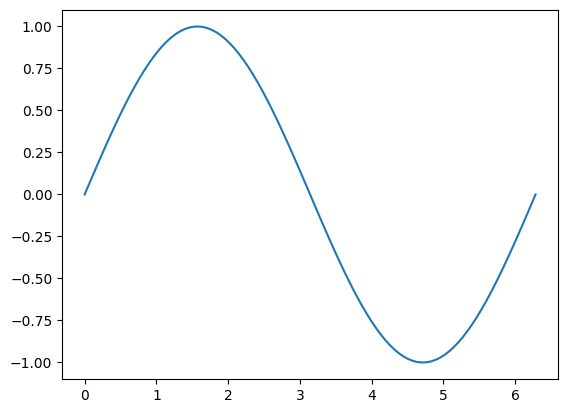

In [24]:
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

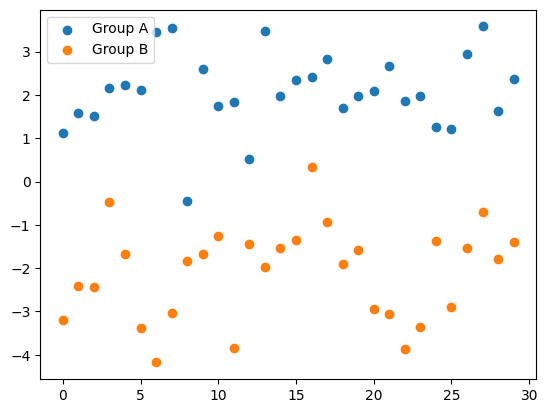

In [25]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
plt.scatter(range(30), group_a, color="C0", label="Group A")
plt.scatter(range(30), group_b, color="C1", label="Group B")
# додати plt.legend(), plt.show()
plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [26]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

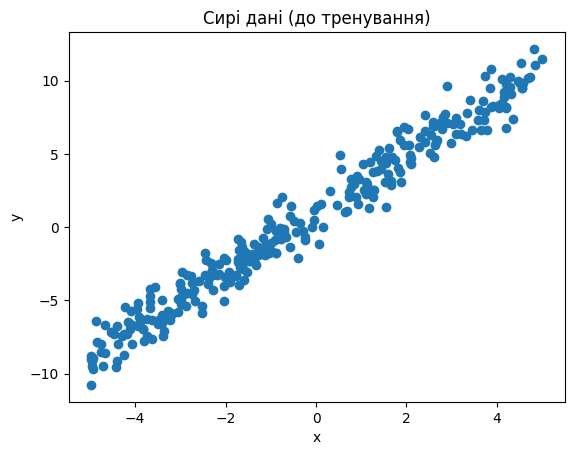

In [27]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1, y1)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сирі дані (до тренування)")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [28]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...
mix = torch.randperm(TASK1_N)

n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)

train_idx = mix[:n_train]
val_idx = mix[n_train:n_train + n_val]
test_idx = mix[n_train + n_val:]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [29]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


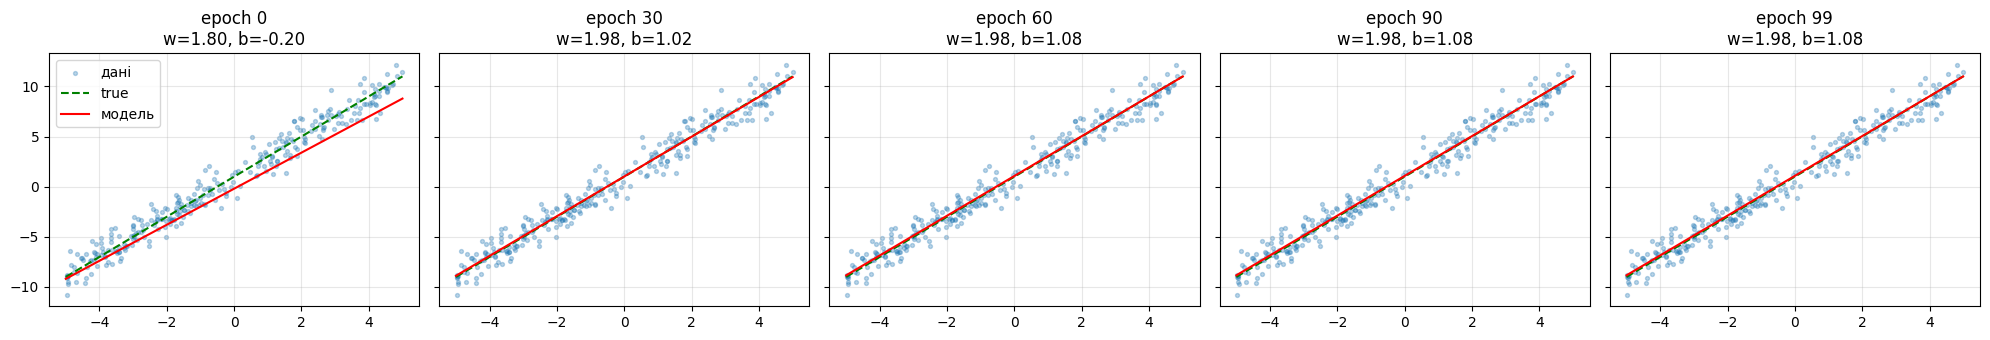

In [30]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій: сон кота та активність

Розглянемо залежність між кількістю годин сну кота протягом доби та тривалістю його активної гри.

Припускаємо, що чим більше часу кіт спить, тим менше часу він витрачає на активну гру. Для спрощеної лінійної моделі вважаємо, що кожна додаткова година сну зменшує час активності приблизно на 8 хвилин.

Модель задаємо як:

$$
y = w \cdot x + b + \varepsilon
$$

де $x$ — кількість годин сну на добу, $y$ - кількість хвилин активної гри, $w=-8$, $b=120$, а $\varepsilon$ - випадковий шум, який враховує індивідуальну поведінку кота та інші фактори.

Отже, очікувана залежність має вигляд:

$$
y = -8x + 120 + \varepsilon
$$

In [31]:
CAT_TRUE_W = -5.0
CAT_TRUE_B = 100.0
CAT_N = 300
CAT_NOISE_STD = 6.0

cat_x = np.random.uniform(8, 16, size=CAT_N)
noise = np.random.normal(0, CAT_NOISE_STD, size=CAT_N)
cat_y = CAT_TRUE_W * cat_x + CAT_TRUE_B + noise

cat_df = pd.DataFrame({
    "sleep_hours": cat_x,
    "play_minutes": cat_y,
})

csv_path = os.path.join(ARTIFACT_DIR, "cat_sleep_activity.csv")
cat_df.to_csv(csv_path, index=False)

print("Дані збережено у:", csv_path)

Дані збережено у: /content/drive/MyDrive/ai_systems/lab1/cat_sleep_activity.csv


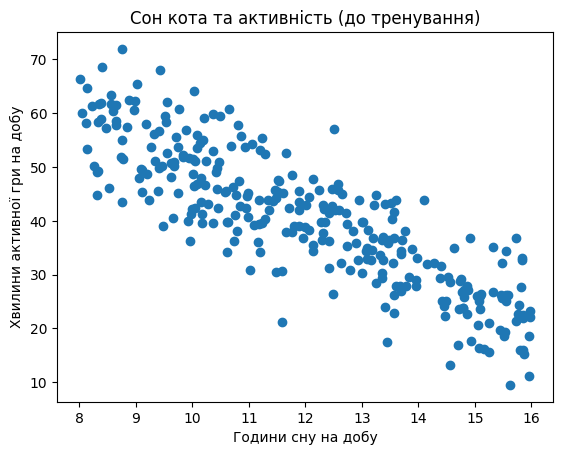

In [32]:
# TODO: scatter cat_x проти cat_y, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(cat_x, cat_y)
plt.xlabel("Години сну на добу")
plt.ylabel("Хвилини активної гри на добу")
plt.title("Сон кота та активність (до тренування)")
plt.show()

In [33]:
# Завантажуємо дані з CSV
cat_df = pd.read_csv(csv_path)
cat_x = torch.tensor(cat_df["sleep_hours"].to_numpy(), dtype=torch.float32).unsqueeze(1)
cat_y = torch.tensor(cat_df["play_minutes"].to_numpy(), dtype=torch.float32).unsqueeze(1)

# Перемішуємо cat_x/cat_y через випадкову перестановку
mix = torch.randperm(CAT_N)

n_train = int(0.70 * CAT_N)
n_val = int(0.15 * CAT_N)

train_idx = mix[:n_train]
val_idx = mix[n_train:n_train + n_val]
test_idx = mix[n_train + n_val:]

cat_x_train, cat_y_train = cat_x[train_idx], cat_y[train_idx]
cat_x_val, cat_y_val = cat_x[val_idx], cat_y[val_idx]
cat_x_test, cat_y_test = cat_x[test_idx], cat_y[test_idx]

print(f"train/val/test: {len(cat_x_train)}/{len(cat_x_val)}/{len(cat_x_test)}")

train/val/test: 210/45/45


In [34]:
def train_model(model, x_train, y_train, optimizer, loss_fn, x_line, true_w, true_b, epochs=100):
    snapshots = []
    losses = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if epoch % 30 == 0 or epoch == epochs - 1:
            with torch.no_grad():
                y_line_pred = model(x_line)

            w = model.weight.item()
            b_centered = model.bias.item()
            b_original = b_centered - 12.0 * w

            snapshots.append((epoch, w, b_original, y_line_pred))

            print(
                f"epoch {epoch:4d}  loss={loss.item():.6f}  "
                f"w={w:.4f} (true {true_w})  "
                f"b={b_original:.4f} (true {true_b})"
            )

    return snapshots, losses

In [41]:
cat_x_train_centered = cat_x_train - 12.0

cat_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(cat_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(8, 16, 100).unsqueeze(1)
x_line_centered = x_line - 12.0

snapshots, losses = train_model(cat_model, cat_x_train_centered, cat_y_train, optimizer, loss_fn, x_line_centered, CAT_TRUE_W, CAT_TRUE_B)

epoch    0  loss=1788.714478  w=-2.4894 (true -5.0)  b=34.0172 (true 100.0)
epoch   30  loss=46.674995  w=-4.5559 (true -5.0)  b=93.2112 (true 100.0)
epoch   60  loss=43.799355  w=-4.5268 (true -5.0)  b=94.3267 (true 100.0)
epoch   90  loss=43.794132  w=-4.5256 (true -5.0)  b=94.3743 (true 100.0)
epoch   99  loss=43.794117  w=-4.5256 (true -5.0)  b=94.3755 (true 100.0)


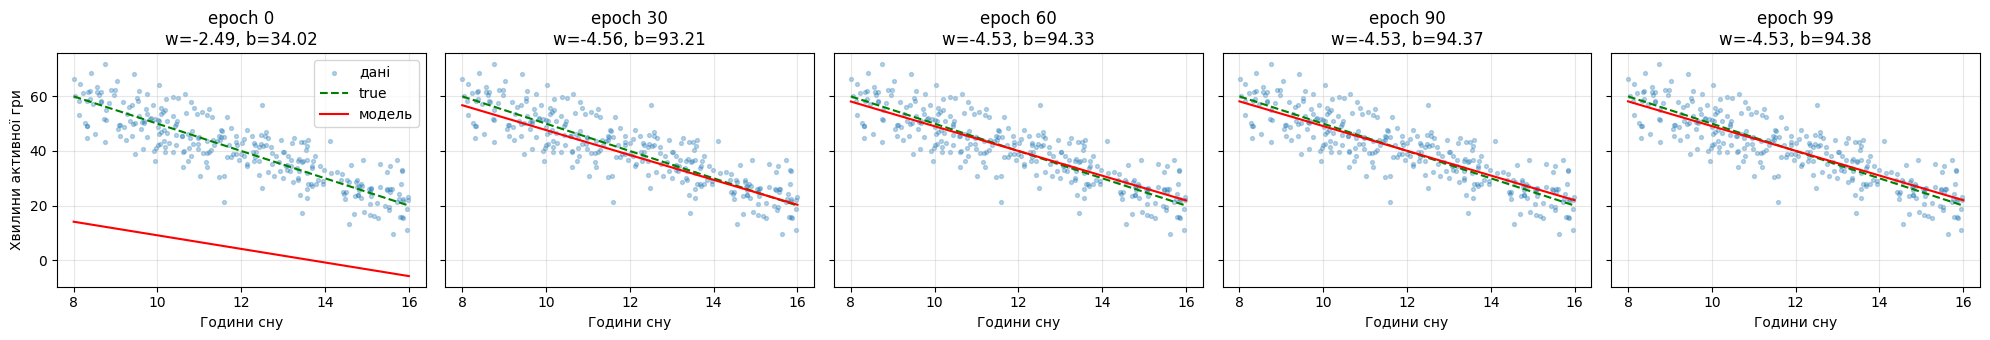

In [42]:
with torch.no_grad():
    y_line_true = CAT_TRUE_W * x_line + CAT_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(cat_x.numpy(), cat_y.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.set_xlabel("Години сну")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Хвилини активної гри")
axes[0].legend()

plt.tight_layout()
plt.show()

In [43]:
def evaluate_model(model, x_test, y_test):
    with torch.no_grad():
        predictions = model(x_test)
        mse = torch.mean((predictions - y_test) ** 2)

    return mse.item()

In [44]:
cat_x_test_centered = cat_x_test - 12.0
test_mse = evaluate_model(cat_model, cat_x_test_centered, cat_y_test)
print(f"Test MSE: {test_mse:.4f}")

Test MSE: 47.0211


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [45]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(cat_model.state_dict(), model_path)
print("Модель збережено у:", model_path)

Модель збережено у: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [46]:
!pip install -q gradio

In [47]:
import gradio as gr

In [48]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(torch.load(model_path, weights_only=True))
loaded_model.eval()

print("Модель завантажено")

Модель завантажено


In [49]:
def predict_activity(sleep_hours):
    x = torch.tensor([[sleep_hours - 12.0]], dtype=torch.float32)

    with torch.no_grad():
        prediction = loaded_model(x)

    return prediction.item()

In [50]:
demo = gr.Interface(
    fn=predict_activity,
    inputs=gr.Number(
        label="Години сну кота",
        minimum=8,
        maximum=16
    ),
    outputs=gr.Number(
        label="Прогноз активної гри (хвилин)"
    ),
    title="Прогноз активності кота",
    description="""
    by Daryna Dzinzilevych IPZ-23-2

    Введіть, скільки годин спав кіт, щоб отримати прогноз його активності.
    """
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2fbd6805e7ed0ada4e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```